# Métodos de Clustering No Supervisado

K-Means, Clustering Jerárquico, DBSCAN y Mezcla Gaussiana usando el dataset Iris de sklearn. Exploración, limpieza, preprocesamiento, cálculo de k, visualización y análisis de resultados.

## 1. Carga y exploración del dataset
Se utiliza el dataset Iris. Se exploran las primeras filas y estadísticas básicas.

In [16]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# os.environ["OMP_NUM_THREADS"] = "1"

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Primeras 5 filas:')
display(df.head())
print('Resumen estadístico:')
display(df.describe())

Primeras 5 filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Resumen estadístico:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 2. Limpieza y preprocesamiento
Revisión de valores faltantes, imputación y tratamiento de outliers. Normalización de datos numéricos.

In [17]:
# Revisar valores faltantes
print('Valores faltantes por columna:')
print(df.isnull().sum())

# Imputación de valores faltantes (si existieran)
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# Tratamiento de outliers con IQR
Q1 = df_imputed.quantile(0.25)
Q3 = df_imputed.quantile(0.75)
IQR = Q3 - Q1
df_clean = df_imputed[~((df_imputed < (Q1 - 1.5 * IQR)) | (df_imputed > (Q3 + 1.5 * IQR))).any(axis=1)]
print(f'Se eliminaron {len(df_imputed) - len(df_clean)} filas por outliers.')

# Normalización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
print('Datos normalizados. Primeras filas:')
display(pd.DataFrame(X_scaled, columns=df.columns).head())

Valores faltantes por columna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64
Se eliminaron 4 filas por outliers.
Datos normalizados. Primeras filas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.910515,1.159151,-1.373764,-1.348525
1,-1.151122,-0.101922,-1.373764,-1.348525
2,-1.391729,0.402507,-1.430841,-1.348525
3,-1.512032,0.150292,-1.316687,-1.348525
4,-1.030819,1.411365,-1.373764,-1.348525


## 3. Cálculo del número óptimo de clusters (k)
Se utiliza el método del codo y el Silhouette Score para determinar el valor óptimo de k para K-Means.

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

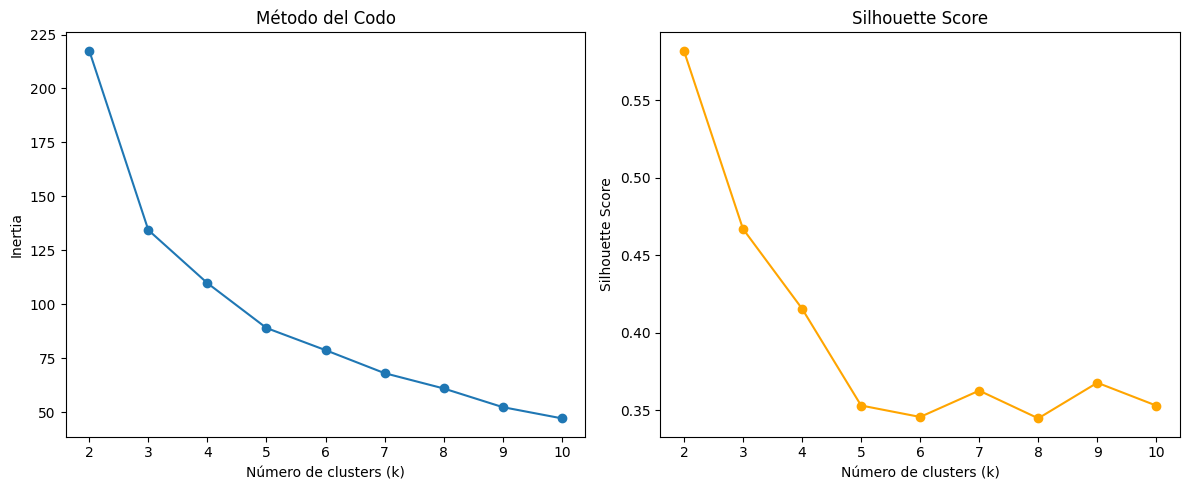

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
sil_scores = []
K = range(2, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inertia')
plt.title('Método del Codo')
plt.subplot(1,2,2)
plt.plot(K, sil_scores, marker='o', color='orange')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

## 3.1 Cálculo del número óptimo de clusters (k)
Se utiliza el método del codo y el Silhouette Score para determinar el valor óptimo de k para K-Means.


In [19]:

# Selección automática de k por Silhouette Score
def select_k_silhouette(K, sil_scores):
    best_index = np.argmax(sil_scores)
    return K[best_index], sil_scores[best_index]

k_sil, score_sil = select_k_silhouette(list(K), sil_scores)
print(f'Mejor k por Silhouette Score: {k_sil} (score={score_sil:.3f})')

# Selección automática de k por método del codo
def select_k_elbow(K, inertia):
    inertia_diff = np.diff(inertia)
    inertia_diff2 = np.diff(inertia_diff)
    elbow_index = np.argmax(inertia_diff2) + 1  # +1 por el diff
    return K[elbow_index], inertia[elbow_index]

k_elbow, inertia_elbow = select_k_elbow(list(K), inertia)
print(f'Mejor k por método del codo: {k_elbow} (inertia={inertia_elbow:.2f})')

# Promedio de ambos métodos (opcional)
k_auto = int(np.round((k_sil + k_elbow) / 2))
print(f'k sugerido combinando ambos métodos: {k_auto}')

Mejor k por Silhouette Score: 2 (score=0.582)
Mejor k por método del codo: 3 (inertia=134.35)
k sugerido combinando ambos métodos: 2


## 4. K-Means Clustering
Aplicación de K-Means con el k óptimo. Visualización de los clusters en 2D usando PCA.

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adria\AppData\Local\Temp\ipykernel_37240\3714432256.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean.loc[:, 'cluster_kmeans'] = clusters_kmeans


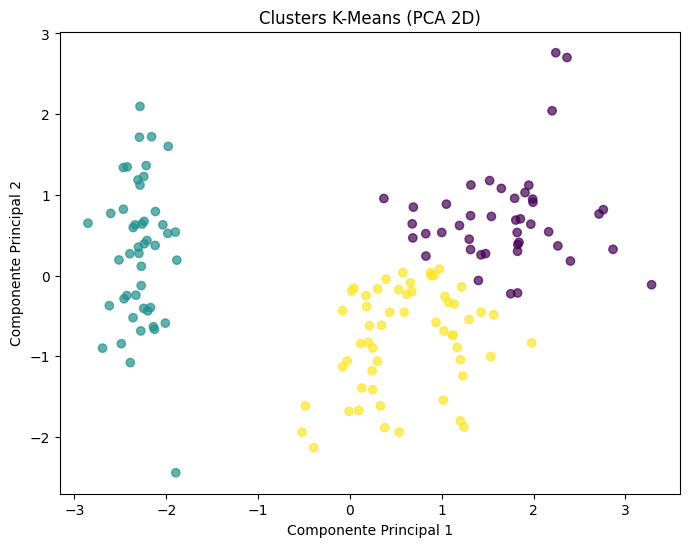

In [20]:
optimal_k = 3  # Cambia este valor según el resultado anterior
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)
# df_clean['cluster_kmeans'] = clusters_kmeans
df_clean.loc[:, 'cluster_kmeans'] = clusters_kmeans

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_kmeans, cmap='viridis', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Clusters K-Means (PCA 2D)')
plt.show()

## 5. Clustering Jerárquico
Aplicación de Agglomerative Clustering y visualización del dendrograma.

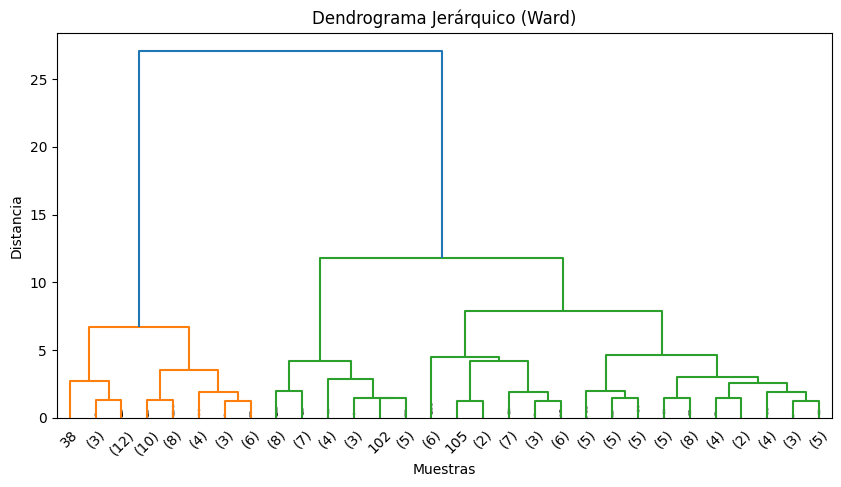

C:\Users\adria\AppData\Local\Temp\ipykernel_37240\3662555241.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean.loc[:, 'cluster_agglo'] = clusters_agglo


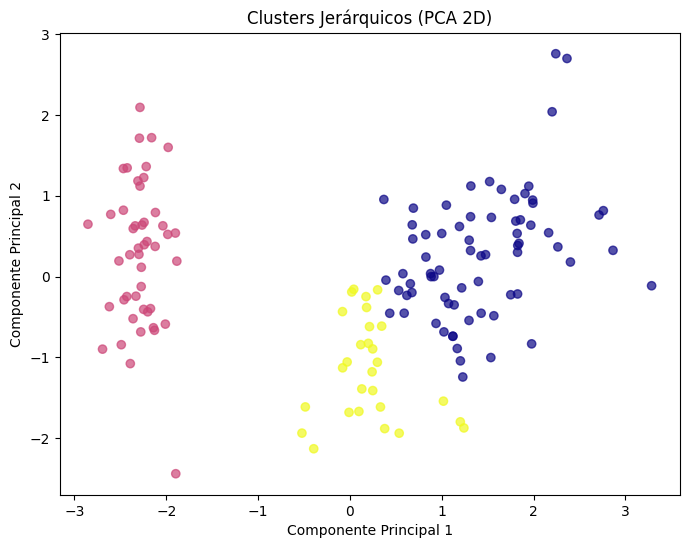

In [21]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.title('Dendrograma Jerárquico (Ward)')
plt.xlabel('Muestras')
plt.ylabel('Distancia')
plt.show()

agglo = AgglomerativeClustering(n_clusters=optimal_k)
clusters_agglo = agglo.fit_predict(X_scaled)
# df_clean['cluster_agglo'] = clusters_agglo
df_clean.loc[:, 'cluster_agglo'] = clusters_agglo
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_agglo, cmap='plasma', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Clusters Jerárquicos (PCA 2D)')
plt.show()

## 6. DBSCAN
Aplicación de DBSCAN y visualización de los clusters. Se recomienda ajustar eps y min_samples según el dataset.

C:\Users\adria\AppData\Local\Temp\ipykernel_37240\2284711489.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean.loc[:, 'cluster_dbscan'] = clusters_dbscan


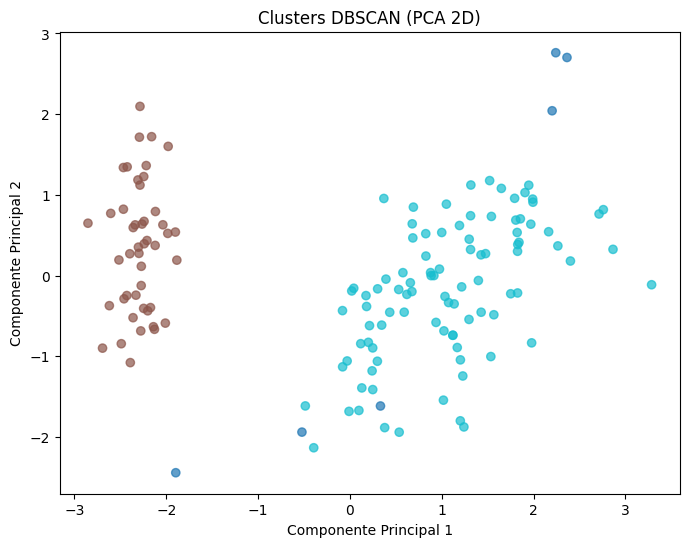

Etiquetas DBSCAN: -1 indica ruido/anomalía


In [22]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.7, min_samples=5)
clusters_dbscan = dbscan.fit_predict(X_scaled)
# df_clean['cluster_dbscan'] = clusters_dbscan
df_clean.loc[:, 'cluster_dbscan'] = clusters_dbscan
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_dbscan, cmap='tab10', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Clusters DBSCAN (PCA 2D)')
plt.show()
print('Etiquetas DBSCAN: -1 indica ruido/anomalía')

## 7. Mezcla Gaussiana (Gaussian Mixture Model)
Aplicación de GMM y visualización de los clusters probabilísticos.

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\adria\AppData\Local\Temp\ipykernel_37240\1938433342.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean.loc[:, 'cluster_gmm'] = clusters_gmm


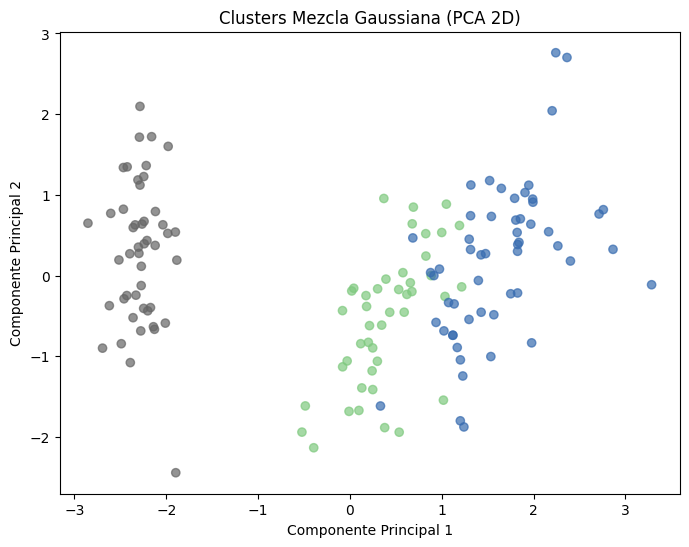

In [23]:
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=optimal_k, random_state=42)
clusters_gmm = gmm.fit_predict(X_scaled)
# df_clean['cluster_gmm'] = clusters_gmm
df_clean.loc[:, 'cluster_gmm'] = clusters_gmm
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_gmm, cmap='Accent', alpha=0.7)
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.title('Clusters Mezcla Gaussiana (PCA 2D)')
plt.show()

## 8. Comparación y análisis de resultados
- Compara los clusters obtenidos por cada método.
- Analiza la estabilidad, la cantidad de ruido/anomalías detectadas y la interpretación de los grupos.
- Visualiza las diferencias y similitudes entre los métodos.

**Comentarios:**
- K-Means y GMM suelen dar resultados similares en datos bien separados.
- Clustering jerárquico permite visualizar la estructura de los datos.
- DBSCAN detecta ruido y grupos de forma arbitraria, útil para datos con formas no esféricas.

Ajusta los hiperparámetros según el comportamiento observado en las visualizaciones y métricas.

## 9. Interpretación de Clusters y Métricas Adicionales

En esta sección se analizan los clusters obtenidos, se calculan métricas adicionales y se discute qué aspectos son relevantes al interpretar los resultados de clustering.

### Métricas adicionales:
- **Silhouette Score:** Evalúa la cohesión y separación de los clusters. Valores cercanos a 1 indican buena separación.
- **Davies-Bouldin Index:** Valores bajos indican clusters bien separados y compactos.
- **Homogeneity, Completeness, V-Measure:** Si se dispone de etiquetas verdaderas (como en Iris), permiten comparar la calidad del clustering respecto a la clasificación real.

### ¿Qué buscar y analizar?
- **Distribución de los clusters:** ¿Son de tamaño similar o hay desequilibrio?
- **Separación entre clusters:** ¿Están bien definidos o hay solapamiento?
- **Presencia de ruido/anomalías:** Especialmente relevante en DBSCAN.
- **Correspondencia con clases reales:** Si existen etiquetas, ¿los clusters reflejan las clases verdaderas?
- **Variables relevantes:** ¿Qué variables explican mejor la separación entre grupos?
- **Estabilidad:** ¿Los resultados cambian mucho al modificar hiperparámetros?

### Ejemplo de cálculo de métricas adicionales:

In [24]:
# Ejemplo de cálculo de métricas adicionales y análisis de clusters
from sklearn.metrics import davies_bouldin_score, homogeneity_score, completeness_score, v_measure_score
true_labels = iris.target[:len(df_clean)]  # Ajustar si se eliminaron filas por outliers

# Silhouette Score para cada método
print('Silhouette KMeans:', silhouette_score(X_scaled, df_clean['cluster_kmeans']))
print('Silhouette Agglomerative:', silhouette_score(X_scaled, df_clean['cluster_agglo']))
print('Silhouette DBSCAN:', silhouette_score(X_scaled, df_clean['cluster_dbscan']))
print('Silhouette GMM:', silhouette_score(X_scaled, df_clean['cluster_gmm']))

# Davies-Bouldin Index
print('Davies-Bouldin KMeans:', davies_bouldin_score(X_scaled, df_clean['cluster_kmeans']))
print('Davies-Bouldin Agglomerative:', davies_bouldin_score(X_scaled, df_clean['cluster_agglo']))
print('Davies-Bouldin GMM:', davies_bouldin_score(X_scaled, df_clean['cluster_gmm']))
# DBSCAN puede dar error si hay solo un cluster, por lo que se omite si hay muchos -1

# Si hay etiquetas verdaderas, comparar con ellas
print('Homogeneity KMeans:', homogeneity_score(true_labels, df_clean['cluster_kmeans']))
print('Completeness KMeans:', completeness_score(true_labels, df_clean['cluster_kmeans']))
print('V-Measure KMeans:', v_measure_score(true_labels, df_clean['cluster_kmeans']))

# Análisis de distribución de clusters
print('Distribución KMeans:', df_clean['cluster_kmeans'].value_counts())
print('Distribución Agglomerative:', df_clean['cluster_agglo'].value_counts())
print('Distribución DBSCAN:', df_clean['cluster_dbscan'].value_counts())
print('Distribución GMM:', df_clean['cluster_gmm'].value_counts())

Silhouette KMeans: 0.46704048699050305
Silhouette Agglomerative: 0.42943171314509854
Silhouette DBSCAN: 0.511243121003672
Silhouette GMM: 0.3681133883088483
Davies-Bouldin KMeans: 0.8310890986740037
Davies-Bouldin Agglomerative: 0.8147286922527045
Davies-Bouldin GMM: 1.1107738759409418
Homogeneity KMeans: 0.5827659635750114
Completeness KMeans: 0.5856466923264219
V-Measure KMeans: 0.5842027767232898
Distribución KMeans: cluster_kmeans
2    56
1    47
0    43
Name: count, dtype: int64
Distribución Agglomerative: cluster_agglo
0    71
1    47
2    28
Name: count, dtype: int64
Distribución DBSCAN: cluster_dbscan
 1    94
 0    46
-1     6
Name: count, dtype: int64
Distribución GMM: cluster_gmm
1    55
2    47
0    44
Name: count, dtype: int64
